# Experiment 013: 7B base-to-GRPO three-seed analysis

Check all three completed 013 base-start GRPO runs and compare each seed with
the matching 013 GSM8K-SFT-to-GRPO run. Seeds 1 and 2 are the
fixed exploratory replication arms.

This is the final of this stage, so I also apply the registered
cross-scale rule to all twelve matched route pairs. Generative exact match is
primary and the letter-probability probe remains diagnostic. Reading saved
artifacts only and does not need a GPU. Figures are saved to
`analysis/figures/013_4/`.


In [1]:
# find the repo root and load the three matched 7b route pairs
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from analysis.plotting import heatmap_text_color
from analysis.stats import align_pred_rows, holm, mcnemar_exact, paired_delta_ci
from data.subjects import tier_of

RES = ROOT / "results"
FIG = ROOT / "analysis" / "figures" / "013_4"
FIG.mkdir(parents=True, exist_ok=True)

SEEDS = (0, 1, 2)
TIERS = ("easy", "medium", "hard")
COLORS = {0: "#4C78A8", 1: "#F58518", 2: "#54A24B"}
ROUTE_COLORS = {"base to GRPO": "#4C78A8", "SFT to GRPO": "#E45756"}

def jload(path):
    with open(path) as handle:
        return json.load(handle)

def jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]

def retier(rows):
    # rebuild tiers from the current subject mapping
    rebuilt = []
    for row in rows:
        row = dict(row)
        row["tier"] = tier_of(row["subject"])
        rebuilt.append(row)
    return rebuilt

def overall(rows):
    return float(np.mean([row["correct"] for row in rows]))

def grouped_accuracy(rows, field, value):
    selected = [row["correct"] for row in rows if row[field] == value]
    return float(np.mean(selected))

def load_run(path):
    return {
        "preds": retier(jsonl(path / "grpo_preds.jsonl")),
        "probe": retier(jsonl(path / "grpo_logprob_preds.jsonl")),
        "train": jload(path / "grpo_trainlog.json"),
        "eval": jload(path / "grpo_eval.json"),
        "probe_eval": jload(path / "grpo_logprob.json"),
        "manifest": jload(path / "manifest.json"),
    }

def metric_series(rows, key):
    selected = [row for row in rows if key in row and "step" in row]
    return (
        np.array([row["step"] for row in selected]),
        np.array([row[key] for row in selected], dtype=float),
    )

def smooth(values, window=15):
    # use a rolling mean because rollout metrics are noisy
    if len(values) < window:
        return values
    return np.convolve(values, np.ones(window) / window, mode="valid")

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    print("saved", name)

BASE = {
    seed: load_run(RES / f"013_COLAB_FULL_B7_base_grpo_seed{seed}")
    for seed in SEEDS
}
WARM = {
    seed: load_run(RES / f"013_COLAB_FULL_B7_sft_grpo_seed{seed}")
    for seed in SEEDS
}
RAW_GEN = retier(jsonl(RES / "base_evals" / "013_COLAB_FULL_B7" / "base_preds.jsonl"))
RAW_PROBE = retier(jsonl(RES / "base_evals" / "013_COLAB_FULL_B7" / "base_logprob_preds.jsonl"))

for seed in SEEDS:
    reward_steps = [row["step"] for row in BASE[seed]["train"] if "reward" in row]
    assert reward_steps == list(range(1, 501)), f"seed {seed}: incomplete training history"
    for route in (BASE, WARM):
        assert len(route[seed]["preds"]) == 1884
        assert len(route[seed]["probe"]) == 1884
        assert route[seed]["manifest"]["seed"] == seed
    left, right = align_pred_rows(BASE[seed]["preds"], WARM[seed]["preds"])
    assert len(left) == len(right) == 1884
    assert BASE[seed]["manifest"]["gpu"]["device"] == "NVIDIA A100-SXM4-80GB"
    assert BASE[seed]["manifest"]["config"]["exec"]["allow_oom_fallback"] is False
    if seed in (1, 2):
        assert BASE[seed]["manifest"]["exploratory"] is True

assert len(RAW_GEN) == len(RAW_PROBE) == 1884
print("loaded three complete 013 base runs and three matched warm runs")


loaded three complete 013 base runs and three matched warm runs


## 1. Run health and completion

Completion checks stay separate from the accuracy results.


In [2]:
# summarise completion, environment and memory for all three base-route seeds
health_rows = []
for seed, data in BASE.items():
    manifest = data["manifest"]
    timings = manifest["timings_sec"]
    reward_rows = [row for row in data["train"] if "reward" in row]
    health_rows.append({
        "seed": seed,
        "status": "original" if seed == 0 else "exploratory",
        "steps": len(reward_rows),
        "gen_rows": len(data["preds"]),
        "probe_rows": len(data["probe"]),
        "dtype": manifest["resolved_dtype"],
        "gpu": manifest["gpu"]["device"],
        "peak_vram_gb": manifest["gpu"]["peak_vram_gb"],
        "train_hours": timings["grpo_train"] / 3600,
        "gen_eval_hours": timings["grpo_eval"] / 3600,
    })
health_tbl = pd.DataFrame(health_rows).set_index("seed")
display(health_tbl.round(3))


,status,steps,gen_rows,probe_rows,dtype,gpu,peak_vram_gb,train_hours,gen_eval_hours
seed,,,,,,,,,
0,original,500,1884,1884,bfloat16,NVIDIA A100-SXM4-80GB,73.433,3.753,0.694
1,exploratory,500,1884,1884,bfloat16,NVIDIA A100-SXM4-80GB,71.449,3.942,0.788
2,exploratory,500,1884,1884,bfloat16,NVIDIA A100-SXM4-80GB,72.838,3.833,0.812


## 2. GRPO training behaviour

The same reward and rollout diagnostics are shown for each seed. The format
reward is divided by its 0.2 weight so it reads as rollout compliance.


saved fig01_training_rewards


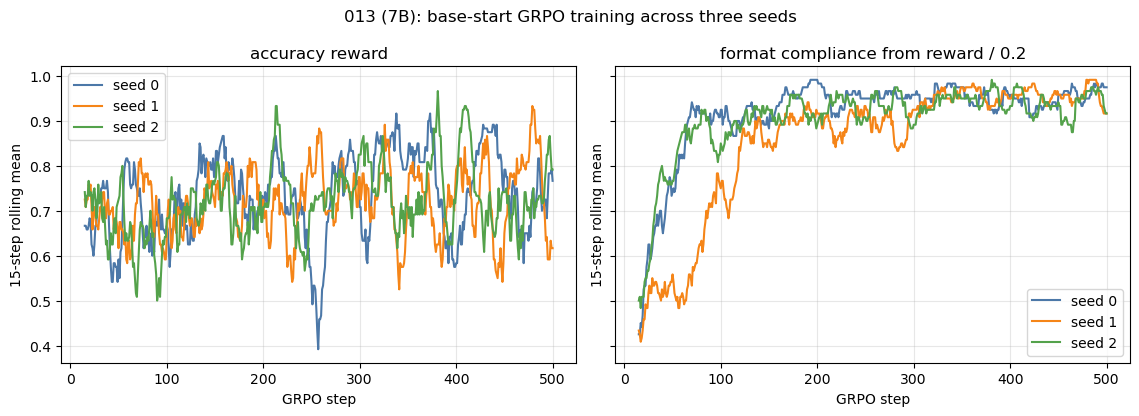

In [3]:
# compare accuracy and format reward across all 500 GRPO steps
window = 15
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
for seed, data in BASE.items():
    steps, accuracy_reward = metric_series(data["train"], "rewards/accuracy_reward/mean")
    _, format_reward = metric_series(data["train"], "rewards/format_reward/mean")
    axes[0].plot(steps[window - 1:], smooth(accuracy_reward, window), color=COLORS[seed], label=f"seed {seed}")
    axes[1].plot(steps[window - 1:], smooth(format_reward, window) / 0.2, color=COLORS[seed], label=f"seed {seed}")
axes[0].set_title("accuracy reward")
axes[1].set_title("format compliance from reward / 0.2")
for ax in axes:
    ax.set_xlabel("GRPO step")
    ax.set_ylabel("15-step rolling mean")
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("013 (7B): base-start GRPO training across three seeds")
fig.tight_layout()
save(fig, "fig01_training_rewards")
plt.show()


saved fig02_training_diagnostics


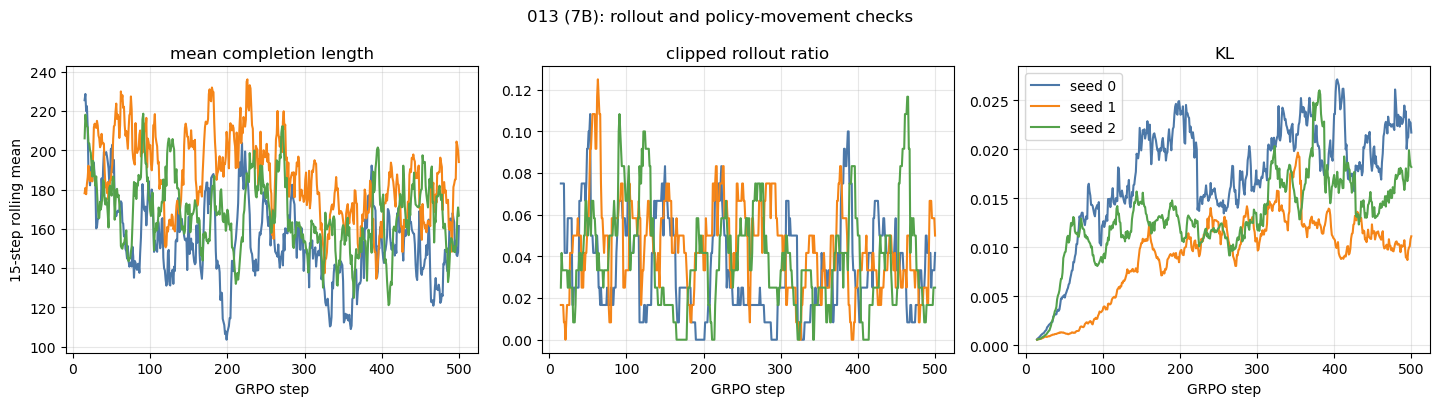

In [4]:
# compare rollout length, clipping and KL without hiding seed variation
panels = [
    ("completions/mean_length", "mean completion length"),
    ("completions/clipped_ratio", "clipped rollout ratio"),
    ("kl", "KL"),
]
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.1))
for ax, (key, title) in zip(axes, panels):
    for seed, data in BASE.items():
        steps, values = metric_series(data["train"], key)
        ax.plot(steps[window - 1:], smooth(values, window), color=COLORS[seed], label=f"seed {seed}")
    ax.set_title(title)
    ax.set_xlabel("GRPO step")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("15-step rolling mean")
axes[-1].legend()
fig.suptitle("013 (7B): rollout and policy-movement checks")
fig.tight_layout()
save(fig, "fig02_training_diagnostics")
plt.show()


## 3. Three-seed base-to-GRPO endpoint

The shared raw-base result provides the before-training reference. The three
post-GRPO seeds show whether the smaller 7B gain repeats and whether the final
endpoint stays stable.


saved fig03_raw_to_grpo_by_tier


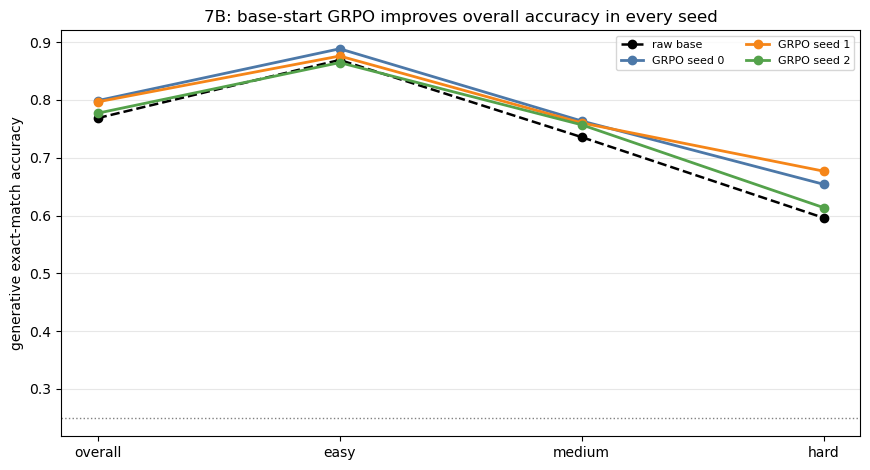

In [5]:
# compare the raw base with all three base-route endpoints by tier
labels = ("overall", *TIERS)
raw_values = [overall(RAW_GEN)] + [grouped_accuracy(RAW_GEN, "tier", tier) for tier in TIERS]
seed_values = {
    seed: [overall(data["preds"])] + [grouped_accuracy(data["preds"], "tier", tier) for tier in TIERS]
    for seed, data in BASE.items()
}

fig, ax = plt.subplots(figsize=(8.8, 4.8))
xpos = np.arange(len(labels))
ax.plot(xpos, raw_values, "o--", color="black", lw=1.8, label="raw base")
for seed in SEEDS:
    ax.plot(xpos, seed_values[seed], "o-", color=COLORS[seed], lw=2, label=f"GRPO seed {seed}")
ax.axhline(0.25, color="grey", ls=":", lw=1)
ax.set_xticks(xpos)
ax.set_xticklabels(labels)
ax.set_ylabel("generative exact-match accuracy")
ax.set_title("7B: base-start GRPO improves overall accuracy in every seed")
ax.grid(alpha=0.3, axis="y")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
save(fig, "fig03_raw_to_grpo_by_tier")
plt.show()


saved fig04_accuracy_format_states


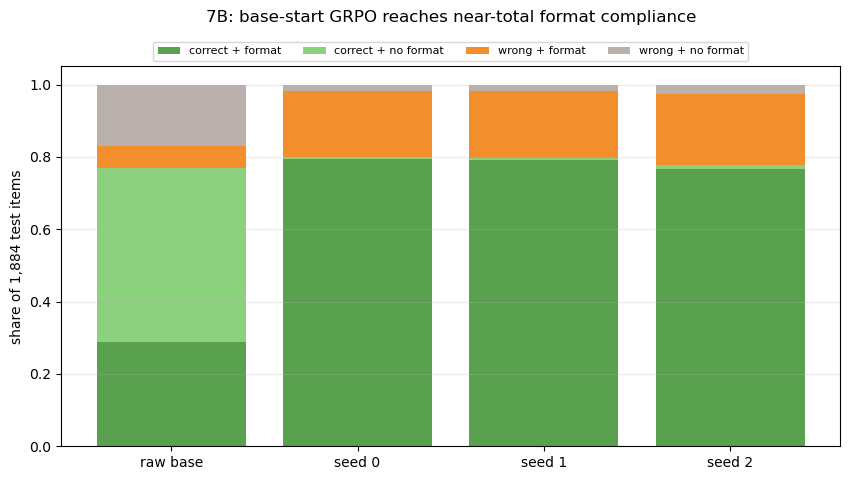

,correct + format,correct + no format,wrong + format,wrong + no format
raw base,0.2882,0.4804,0.0610,0.1704
seed 0,0.7946,0.0042,0.1821,0.0191
seed 1,0.7914,0.0053,0.1842,0.0191
seed 2,0.7665,0.0106,0.1980,0.0249


In [6]:
# split every endpoint into correctness and format states
state_labels = ("correct + format", "correct + no format", "wrong + format", "wrong + no format")
state_colors = ("#59A14F", "#8CD17D", "#F28E2B", "#BAB0AC")
conditions = [("raw base", RAW_GEN)] + [(f"seed {seed}", BASE[seed]["preds"]) for seed in SEEDS]
state_values = []
for _, rows in conditions:
    state_values.append([
        np.mean([row["correct"] and row["format_ok"] for row in rows]),
        np.mean([row["correct"] and not row["format_ok"] for row in rows]),
        np.mean([not row["correct"] and row["format_ok"] for row in rows]),
        np.mean([not row["correct"] and not row["format_ok"] for row in rows]),
    ])
state_values = np.array(state_values)

fig, ax = plt.subplots(figsize=(8.6, 4.9))
bottom = np.zeros(len(conditions))
for column, (label, color) in enumerate(zip(state_labels, state_colors)):
    ax.bar(range(len(conditions)), state_values[:, column], bottom=bottom, color=color, label=label)
    bottom += state_values[:, column]
ax.set_xticks(range(len(conditions)))
ax.set_xticklabels([label for label, _ in conditions])
ax.set_ylabel("share of 1,884 test items")
ax.set_title("7B: base-start GRPO reaches near-total format compliance", pad=32)
ax.legend(fontsize=8, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0))
ax.grid(alpha=0.25, axis="y")
fig.tight_layout()
save(fig, "fig04_accuracy_format_states")
plt.show()

format_tbl = pd.DataFrame(state_values, index=[label for label, _ in conditions], columns=state_labels)
display(format_tbl.round(4))


## 4. Matched warm-start comparison

Each comparison uses the same seed and the same 1,884 MMLU items. Positive
deltas mean the GSM8K SFT warm start produced the stronger GRPO endpoint.
Holm correction is applied across the three overall seed comparisons.


saved fig05_matched_route_endpoints


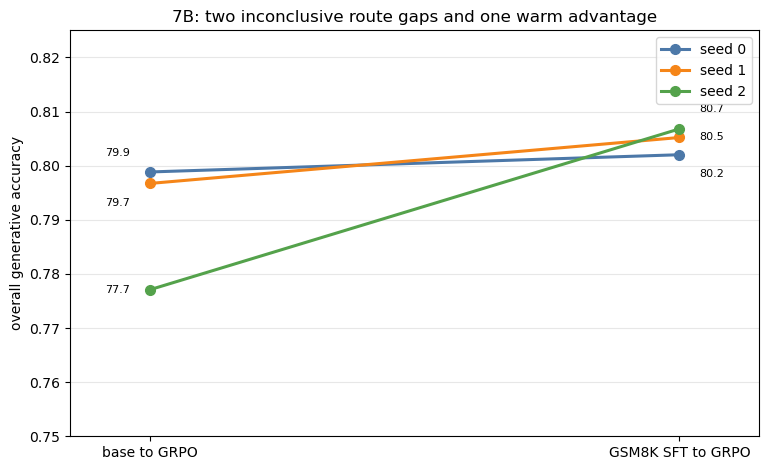

,base_grpo,warm_grpo,warm_minus_base,ci_low,ci_high,mcnemar_p,base_only,warm_only,holm_p,reading
seed,,,,,,,,,,
0,0.79883,0.80202,0.00318,-0.01433,0.02017,0.76097,132,138,0.77617,inconclusive
1,0.79671,0.80520,0.00849,-0.00955,0.02654,0.38809,143,159,0.77617,inconclusive
2,0.77707,0.80679,0.02972,0.01221,0.04777,0.00145,122,178,0.00436,material warm advantage


In [7]:
# calculate the registered matched-seed route comparison
route_rows = []
raw_p = []
for seed in SEEDS:
    base_rows, warm_rows = align_pred_rows(BASE[seed]["preds"], WARM[seed]["preds"])
    base_correct = [row["correct"] for row in base_rows]
    warm_correct = [row["correct"] for row in warm_rows]
    delta, low, high = paired_delta_ci(base_correct, warm_correct, seed=800 + seed)
    base_only = sum(a and not b for a, b in zip(base_correct, warm_correct))
    warm_only = sum((not a) and b for a, b in zip(base_correct, warm_correct))
    p_value = mcnemar_exact(warm_only, base_only)
    raw_p.append(p_value)
    route_rows.append({
        "seed": seed,
        "base_grpo": np.mean(base_correct),
        "warm_grpo": np.mean(warm_correct),
        "warm_minus_base": delta,
        "ci_low": low,
        "ci_high": high,
        "mcnemar_p": p_value,
        "base_only": base_only,
        "warm_only": warm_only,
    })
adjusted = holm(raw_p)
for row, adjusted_p in zip(route_rows, adjusted):
    row["holm_p"] = adjusted_p
    if abs(row["warm_minus_base"]) >= 0.02 and adjusted_p < 0.05:
        row["reading"] = "material warm advantage" if row["warm_minus_base"] > 0 else "material base advantage"
    elif row["ci_low"] >= -0.02 and row["ci_high"] <= 0.02:
        row["reading"] = "equivalent"
    else:
        row["reading"] = "inconclusive"
route_tbl = pd.DataFrame(route_rows).set_index("seed")

fig, ax = plt.subplots(figsize=(7.8, 4.8))
left_offsets = {0: 14, 1: -14, 2: 0}
right_offsets = {0: -14, 1: 0, 2: 14}
for seed, row in route_tbl.iterrows():
    values = [row["base_grpo"], row["warm_grpo"]]
    ax.plot([0, 1], values, "o-", lw=2.2, ms=7, color=COLORS[seed], label=f"seed {seed}")
    ax.annotate(f"{100 * values[0]:.1f}", (0, values[0]), xytext=(-14, left_offsets[seed]), textcoords="offset points", ha="right", va="center", fontsize=8)
    ax.annotate(f"{100 * values[1]:.1f}", (1, values[1]), xytext=(14, right_offsets[seed]), textcoords="offset points", ha="left", va="center", fontsize=8)
ax.set_xlim(-0.15, 1.15)
ax.set_xticks([0, 1])
ax.set_xticklabels(["base to GRPO", "GSM8K SFT to GRPO"])
ax.set_ylabel("overall generative accuracy")
ax.set_ylim(0.75, 0.825)
ax.set_title("7B: two inconclusive route gaps and one warm advantage")
ax.grid(alpha=0.3, axis="y")
ax.legend()
fig.tight_layout()
save(fig, "fig05_matched_route_endpoints")
plt.show()

display(route_tbl.round(5))


saved fig06_route_delta_by_tier


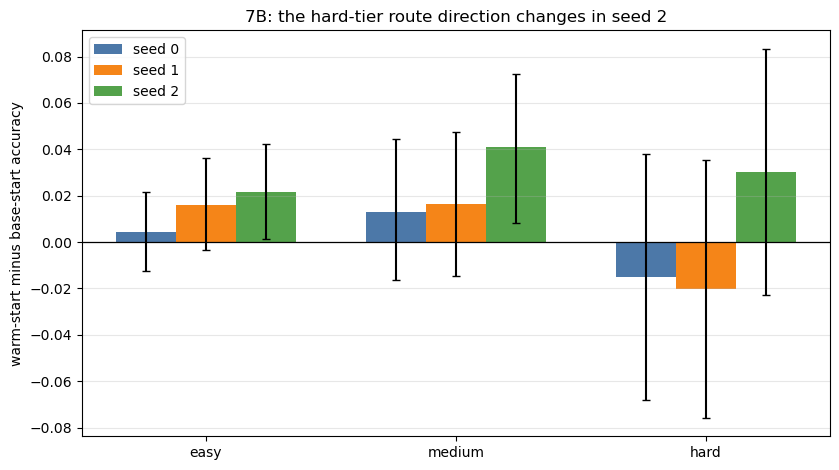

delta  ci_low  ci_high
seed tier                           
0    easy    0.0046 -0.0125   0.0216
     medium  0.0131 -0.0164   0.0443
     hard   -0.0152 -0.0682   0.0379
1    easy    0.0159 -0.0034   0.0364
     medium  0.0164 -0.0148   0.0476
     hard   -0.0202 -0.0758   0.0354
2    easy    0.0216  0.0011   0.0421
     medium  0.0411  0.0082   0.0722
     hard    0.0303 -0.0227   0.0833

In [8]:
# split the matched route difference by tier for every seed
tier_rows = []
for seed in SEEDS:
    base_rows, warm_rows = align_pred_rows(BASE[seed]["preds"], WARM[seed]["preds"])
    for tier in TIERS:
        pairs = [(a["correct"], b["correct"]) for a, b in zip(base_rows, warm_rows) if a["tier"] == tier]
        base_correct = [a for a, _ in pairs]
        warm_correct = [b for _, b in pairs]
        delta, low, high = paired_delta_ci(base_correct, warm_correct, seed=900 + 10 * seed + TIERS.index(tier))
        tier_rows.append({"seed": seed, "tier": tier, "delta": delta, "ci_low": low, "ci_high": high})
tier_tbl = pd.DataFrame(tier_rows)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
xpos = np.arange(len(TIERS))
width = 0.24
for index, seed in enumerate(SEEDS):
    selected = tier_tbl[tier_tbl["seed"] == seed].set_index("tier").loc[list(TIERS)]
    values = selected["delta"].to_numpy()
    errors = np.vstack([values - selected["ci_low"].to_numpy(), selected["ci_high"].to_numpy() - values])
    positions = xpos + (index - 1) * width
    ax.bar(positions, values, width, yerr=errors, capsize=3, color=COLORS[seed], label=f"seed {seed}")
ax.axhline(0, color="black", lw=0.9)
ax.set_xticks(xpos)
ax.set_xticklabels(TIERS)
ax.set_ylabel("warm-start minus base-start accuracy")
ax.set_title("7B: the hard-tier route direction changes in seed 2")
ax.grid(alpha=0.3, axis="y")
ax.legend()
fig.tight_layout()
save(fig, "fig06_route_delta_by_tier")
plt.show()

display(tier_tbl.set_index(["seed", "tier"]).round(4))


## 5. Format, response length and the knowledge probe

These diagnostics separate improved answer expression from changes in the
underlying letter preference. The raw-base probe is shared across 013 seeds.


saved fig07_route_diagnostics


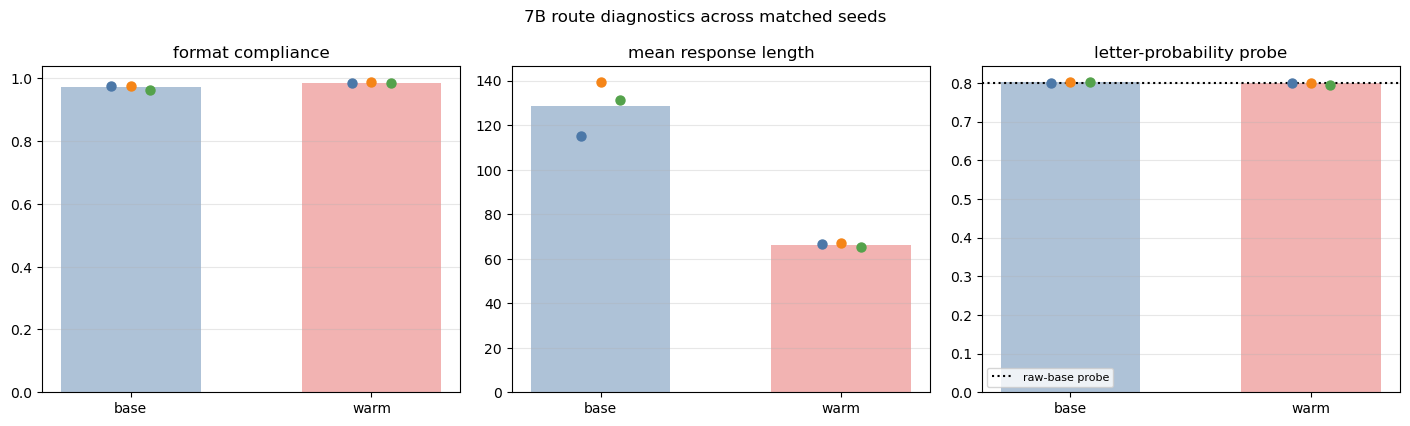

format  mean_length  probe_accuracy  gen_accuracy
route        seed                                                   
base to GRPO 0     0.9766     115.0743          0.7999        0.7988
             1     0.9756     139.4130          0.8020        0.7967
             2     0.9644     131.4639          0.8025        0.7771
SFT to GRPO  0     0.9841      66.4512          0.7999        0.8020
             1     0.9889      66.9135          0.7999        0.8052
             2     0.9846      65.4246          0.7956        0.8068

In [9]:
# compare route diagnostics while keeping all three seeds visible
diagnostic_rows = []
for label, runs in (("base to GRPO", BASE), ("SFT to GRPO", WARM)):
    for seed, data in runs.items():
        diagnostic_rows.append({
            "route": label,
            "seed": seed,
            "format": float(np.mean([row["format_ok"] for row in data["preds"]])),
            "mean_length": float(np.mean([row["n_tokens"] for row in data["preds"]])),
            "probe_accuracy": overall(data["probe"]),
            "gen_accuracy": overall(data["preds"]),
        })
diagnostic_tbl = pd.DataFrame(diagnostic_rows)

panels = [("format", "format compliance"), ("mean_length", "mean response length"), ("probe_accuracy", "letter-probability probe")]
fig, axes = plt.subplots(1, 3, figsize=(14.2, 4.3))
for ax, (metric, title) in zip(axes, panels):
    for x, route in enumerate(("base to GRPO", "SFT to GRPO")):
        values = diagnostic_tbl.loc[diagnostic_tbl["route"] == route, metric].to_numpy()
        ax.bar(x, values.mean(), width=0.58, color=ROUTE_COLORS[route], alpha=0.45)
        for index, value in enumerate(values):
            ax.scatter(x + (index - 1) * 0.08, value, color=COLORS[index], s=42, zorder=3)
    if metric == "probe_accuracy":
        ax.axhline(overall(RAW_PROBE), color="black", ls=":", lw=1.5, label="raw-base probe")
        ax.legend(fontsize=8)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["base", "warm"])
    ax.set_title(title)
    ax.grid(alpha=0.3, axis="y")
fig.suptitle("7B route diagnostics across matched seeds")
fig.tight_layout()
save(fig, "fig07_route_diagnostics")
plt.show()

display(diagnostic_tbl.set_index(["route", "seed"]).round(4))


saved fig08_probe_movement


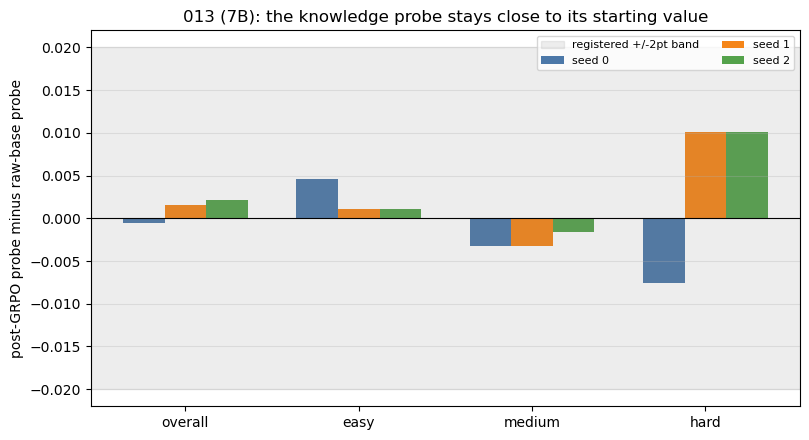

,overall,easy,medium,hard
seed,,,,
0,-0.0005,0.0046,-0.0033,-0.0076
1,0.0016,0.0011,-0.0033,0.0101
2,0.0021,0.0011,-0.0016,0.0101


In [10]:
# measure base-route probe movement against the shared raw-base reference
raw_probe_by_tier = {tier: grouped_accuracy(RAW_PROBE, "tier", tier) for tier in TIERS}
raw_probe_overall = overall(RAW_PROBE)
probe_rows = []
for seed, data in BASE.items():
    row = {"seed": seed, "overall": overall(data["probe"]) - raw_probe_overall}
    for tier in TIERS:
        row[tier] = grouped_accuracy(data["probe"], "tier", tier) - raw_probe_by_tier[tier]
    probe_rows.append(row)
probe_tbl = pd.DataFrame(probe_rows).set_index("seed")

fig, ax = plt.subplots(figsize=(8.2, 4.5))
labels = ["overall", *TIERS]
xpos = np.arange(len(labels))
width = 0.24
for index, seed in enumerate(SEEDS):
    values = probe_tbl.loc[seed, labels].to_numpy(dtype=float)
    ax.bar(xpos + (index - 1) * width, values, width, color=COLORS[seed], label=f"seed {seed}")
ax.axhspan(-0.02, 0.02, color="grey", alpha=0.14, label="registered +/-2pt band")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(xpos)
ax.set_xticklabels(labels)
ax.set_ylabel("post-GRPO probe minus raw-base probe")
ax.set_title("013 (7B): the knowledge probe stays close to its starting value")
ax.grid(alpha=0.3, axis="y")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
save(fig, "fig08_probe_movement")
plt.show()

display(probe_tbl.round(4))


saved fig09_subject_route_matrix


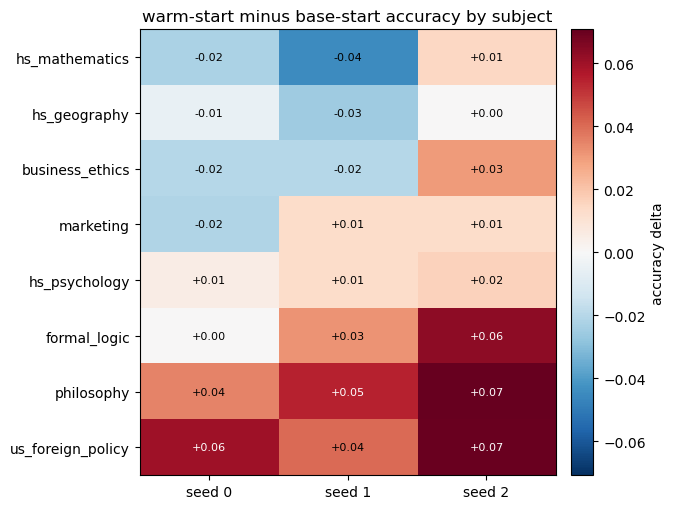

,seed_0,seed_1,seed_2
business_ethics,-0.0200,-0.0200,0.0300
formal_logic,0.0000,0.0317,0.0635
high_school_geography,-0.0051,-0.0253,0.0000
high_school_mathematics,-0.0222,-0.0444,0.0148
high_school_psychology,0.0055,0.0128,0.0165
marketing,-0.0214,0.0128,0.0128
philosophy,0.0354,0.0547,0.0707
us_foreign_policy,0.0600,0.0400,0.0700


In [11]:
# show where the matched route difference agrees or changes across subjects
subjects = sorted({row["subject"] for row in BASE[0]["preds"]})
subject_values = np.zeros((len(subjects), len(SEEDS)))
for column, seed in enumerate(SEEDS):
    base_rows, warm_rows = align_pred_rows(BASE[seed]["preds"], WARM[seed]["preds"])
    for row_index, subject in enumerate(subjects):
        base_acc = grouped_accuracy(base_rows, "subject", subject)
        warm_acc = grouped_accuracy(warm_rows, "subject", subject)
        subject_values[row_index, column] = warm_acc - base_acc
order = np.argsort(subject_values.mean(axis=1))
ordered = subject_values[order]
labels = [subjects[index].replace("high_school_", "hs_") for index in order]
limit = max(abs(ordered.min()), abs(ordered.max()))

fig, ax = plt.subplots(figsize=(6.8, 5.2))
image = ax.imshow(ordered, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto", interpolation="nearest")
for row_index in range(ordered.shape[0]):
    for column in range(ordered.shape[1]):
        color = heatmap_text_color(image, ordered[row_index, column])
        ax.text(column, row_index, f"{ordered[row_index, column]:+.2f}", ha="center", va="center", fontsize=8, color=color)
ax.set_xticks(range(len(SEEDS)))
ax.set_xticklabels([f"seed {seed}" for seed in SEEDS])
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)
ax.set_title("warm-start minus base-start accuracy by subject")
colorbar = fig.colorbar(image, ax=ax, pad=0.03)
colorbar.set_label("accuracy delta")
fig.tight_layout()
save(fig, "fig09_subject_route_matrix")
plt.show()

subject_tbl = pd.DataFrame(subject_values, index=subjects, columns=[f"seed_{seed}" for seed in SEEDS])
display(subject_tbl.round(4))


## 6. Final S4 cross-scale comparison

The registered cross-scale quantity is warm-start minus base-start accuracy
for each matched seed. Slopes use log model size and stay descriptive because
there are only four scale points. Shrinking is called seed-robust only if all
three slopes are negative.


saved fig10_s4_warm_start_gradient


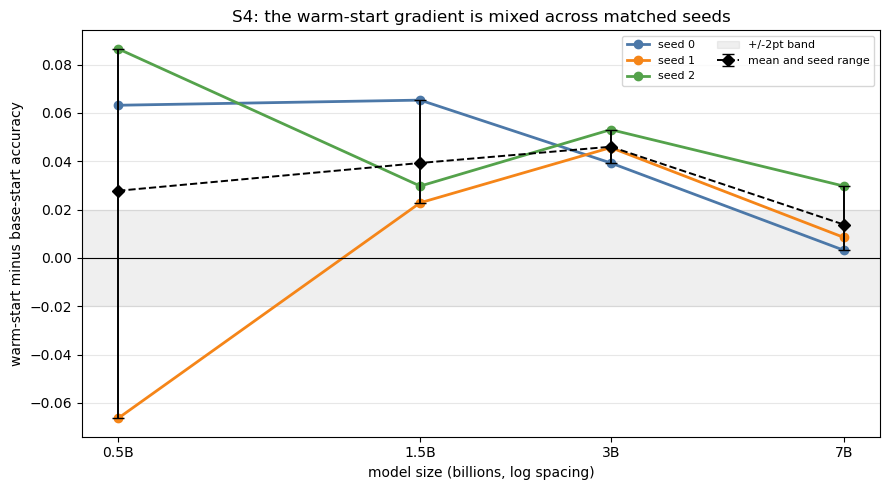

size_b  base_grpo  warm_grpo  warm_minus_base   ci_low  ci_high  \
scale seed                                                                    
0.5B  0        0.5    0.39915    0.46231          0.06316  0.03715  0.09023   
      1        0.5    0.38163    0.31529         -0.06635 -0.09395 -0.03875   
      2        0.5    0.41932    0.50584          0.08652  0.06263  0.10987   
1.5B  0        1.5    0.60881    0.67410          0.06529  0.04459  0.08705   
      1        1.5    0.61200    0.63482          0.02282  0.00212  0.04406   
      2        1.5    0.63270    0.66242          0.02972  0.00955  0.04989   
3B    0        3.0    0.67675    0.71603          0.03928  0.01964  0.05892   
      1        3.0    0.68100    0.72665          0.04565  0.02548  0.06582   
      2        3.0    0.67410    0.72718          0.05308  0.03291  0.07378   
7B    0        7.0    0.79883    0.80202          0.00318 -0.01380  0.02017   
      1        7.0    0.79671    0.80520          0.00849 -0.00955  0.02654   
      2        7.0    0.77707    0.80679          0.02972  0.01168  0.04830   

            mcnemar_p  hard_warm_minus_base   holm_p                  reading  
scale seed                                                                     
0.5B  0       0.00000              -0.01010  0.00001  material warm advantage  
      1       0.00000              -0.04545  0.00001  material base advantage  
      2       0.00000              -0.02778  0.00000  material warm advantage  
1.5B  0       0.00000               0.02778  0.00000  material warm advantage  
      1       0.03676              -0.01010  0.03676  material warm advantage  
      2       0.00494              -0.03283  0.00988  material warm advantage  
3B    0       0.00017              -0.02273  0.00017  material warm advantage  
      1       0.00001              -0.00758  0.00002  material warm advantage  
      2       0.00000              -0.02020  0.00000  material warm advantage  
7B    0       0.76097              -0.01515  0.77617             inconclusive  
      1       0.38809              -0.02020  0.77617             inconclusive  
      2       0.00145               0.03030  0.00436  material warm advantage

,slope_per_log10_b
seed,
0,-0.05282
1,0.07059
2,-0.04247


seed-robust shrinking: False


In [12]:
# rebuild all twelve matched S4 route comparisons from prediction artifacts
S4 = {
    "0.5B": {"size": 0.5, "base": "005_COLAB_FULL_B05_base_grpo_seed{}", "warm": "006_COLAB_FULL_B05_sft_grpo_seed{}"},
    "1.5B": {"size": 1.5, "base": "012_COLAB_FULL_B15_base_grpo_seed{}", "warm": "009_COLAB_FULL_B15_sft_grpo_seed{}"},
    "3B": {"size": 3.0, "base": "004_COLAB_FULL_B3_base_grpo_seed{}", "warm": "003_COLAB_FULL_B3_sft_grpo_seed{}"},
    "7B": {"size": 7.0, "base": "013_COLAB_FULL_B7_base_grpo_seed{}", "warm": "013_COLAB_FULL_B7_sft_grpo_seed{}"},
}

scale_rows = []
for scale_index, (scale, spec) in enumerate(S4.items()):
    pending = []
    raw_p = []
    for seed in SEEDS:
        base_rows = retier(jsonl(RES / spec["base"].format(seed) / "grpo_preds.jsonl"))
        warm_rows = retier(jsonl(RES / spec["warm"].format(seed) / "grpo_preds.jsonl"))
        base_rows, warm_rows = align_pred_rows(base_rows, warm_rows)
        base_correct = [row["correct"] for row in base_rows]
        warm_correct = [row["correct"] for row in warm_rows]
        delta, low, high = paired_delta_ci(base_correct, warm_correct, seed=1000 + 10 * scale_index + seed)
        base_only = sum(a and not b for a, b in zip(base_correct, warm_correct))
        warm_only = sum((not a) and b for a, b in zip(base_correct, warm_correct))
        p_value = mcnemar_exact(warm_only, base_only)
        hard_delta = grouped_accuracy(warm_rows, "tier", "hard") - grouped_accuracy(base_rows, "tier", "hard")
        raw_p.append(p_value)
        pending.append({
            "scale": scale, "size_b": spec["size"], "seed": seed,
            "base_grpo": overall(base_rows), "warm_grpo": overall(warm_rows),
            "warm_minus_base": delta, "ci_low": low, "ci_high": high,
            "mcnemar_p": p_value, "hard_warm_minus_base": hard_delta,
        })
    adjusted = holm(raw_p)
    for row, adjusted_p in zip(pending, adjusted):
        row["holm_p"] = adjusted_p
        if abs(row["warm_minus_base"]) >= 0.02 and adjusted_p < 0.05:
            row["reading"] = "material warm advantage" if row["warm_minus_base"] > 0 else "material base advantage"
        elif row["ci_low"] >= -0.02 and row["ci_high"] <= 0.02:
            row["reading"] = "equivalent"
        else:
            row["reading"] = "inconclusive"
        scale_rows.append(row)

scale_tbl = pd.DataFrame(scale_rows)
scale_order = list(S4)
log_sizes = np.log10([S4[scale]["size"] for scale in scale_order])
fig, ax = plt.subplots(figsize=(9.0, 5.0))
for seed in SEEDS:
    selected = scale_tbl[scale_tbl["seed"] == seed].set_index("scale").loc[scale_order]
    ax.plot(log_sizes, selected["warm_minus_base"], "o-", lw=2, color=COLORS[seed], label=f"seed {seed}")
means = scale_tbl.groupby("scale")["warm_minus_base"].mean().reindex(scale_order)
ranges = scale_tbl.groupby("scale")["warm_minus_base"].agg(["min", "max"]).reindex(scale_order)
errors = np.vstack([means.to_numpy() - ranges["min"].to_numpy(), ranges["max"].to_numpy() - means.to_numpy()])
ax.errorbar(log_sizes, means, yerr=errors, fmt="D--", color="black", capsize=4, lw=1.4, label="mean and seed range")
ax.axhspan(-0.02, 0.02, color="grey", alpha=0.12, label="+/-2pt band")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(log_sizes)
ax.set_xticklabels(scale_order)
ax.set_xlabel("model size (billions, log spacing)")
ax.set_ylabel("warm-start minus base-start accuracy")
ax.set_title("S4: the warm-start gradient is mixed across matched seeds")
ax.grid(alpha=0.3, axis="y")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
save(fig, "fig10_s4_warm_start_gradient")
plt.show()

slope_rows = []
for seed in SEEDS:
    values = scale_tbl[scale_tbl["seed"] == seed].set_index("scale").loc[scale_order, "warm_minus_base"].to_numpy()
    slope_rows.append({"seed": seed, "slope_per_log10_b": float(np.polyfit(log_sizes, values, 1)[0])})
slope_tbl = pd.DataFrame(slope_rows).set_index("seed")
seed_robust_shrinking = bool((slope_tbl["slope_per_log10_b"] < 0).all())
display(scale_tbl.set_index(["scale", "seed"]).round(5))
display(slope_tbl.round(5))
print("seed-robust shrinking:", seed_robust_shrinking)


saved fig11_s4_hard_tier_direction


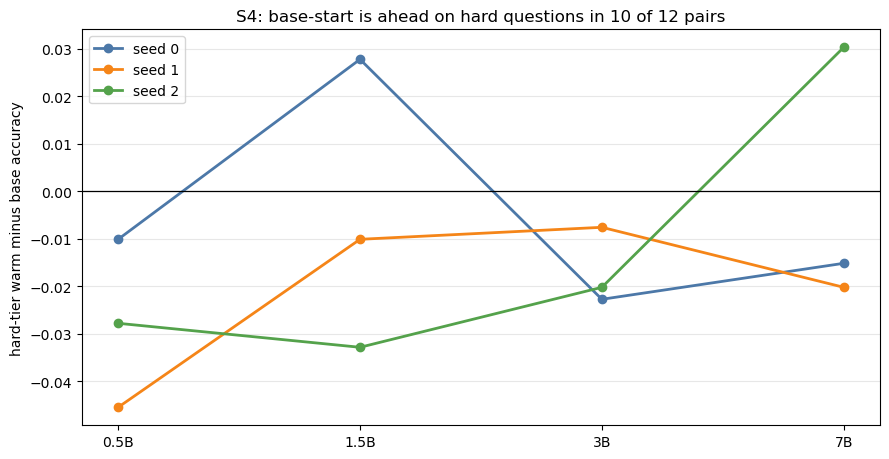

base-start at or above warm-start on hard tier: 10 of 12


In [13]:
# track the hard-tier route direction across all four scales
xpos = np.arange(len(scale_order))
fig, ax = plt.subplots(figsize=(9.0, 4.7))
for seed in SEEDS:
    selected = scale_tbl[scale_tbl["seed"] == seed].set_index("scale").loc[scale_order]
    ax.plot(xpos, selected["hard_warm_minus_base"], "o-", lw=2, color=COLORS[seed], label=f"seed {seed}")
ax.axhline(0, color="black", lw=0.9)
ax.set_xticks(xpos)
ax.set_xticklabels(scale_order)
ax.set_ylabel("hard-tier warm minus base accuracy")
ax.set_title("S4: base-start is ahead on hard questions in 10 of 12 pairs")
ax.grid(alpha=0.3, axis="y")
ax.legend()
fig.tight_layout()
save(fig, "fig11_s4_hard_tier_direction")
plt.show()

hard_base_ahead = int((scale_tbl["hard_warm_minus_base"] <= 0).sum())
print("base-start at or above warm-start on hard tier:", hard_base_ahead, "of", len(scale_tbl))


In [14]:
# save the registered S4 comparison artifact from the exact plotted values
scale_summary = {}
for scale in scale_order:
    rows = scale_tbl[scale_tbl["scale"] == scale]
    categories = rows["reading"].tolist()
    common = categories[0] if len(set(categories)) == 1 and categories[0] != "inconclusive" else None
    scale_summary[scale] = {
        "mean_warm_minus_base": float(rows["warm_minus_base"].mean()),
        "range_warm_minus_base": [float(rows["warm_minus_base"].min()), float(rows["warm_minus_base"].max())],
        "common_reading": common,
        "seeds": [
            {
                "seed": int(row.seed), "base_grpo": float(row.base_grpo),
                "warm_grpo": float(row.warm_grpo), "warm_minus_base": float(row.warm_minus_base),
                "ci": [float(row.ci_low), float(row.ci_high)],
                "mcnemar_p": float(row.mcnemar_p), "holm_p": float(row.holm_p),
                "reading": row.reading, "hard_warm_minus_base": float(row.hard_warm_minus_base),
            }
            for row in rows.itertuples()
        ],
    }

s4_summary = {
    "source_notebook": "013_4_analysis_plots.ipynb",
    "scope": "off-domain GSM8K SFT warm start before MMLU GRPO, not a SimpleRL-Zoo replication",
    "n_items_per_pair": 1884,
    "scales": scale_summary,
    "slopes_per_log10_b": {str(seed): float(slope_tbl.loc[seed, "slope_per_log10_b"]) for seed in SEEDS},
    "seed_robust_shrinking": seed_robust_shrinking,
    "cross_scale_reading": "mixed" if not seed_robust_shrinking else "shrinking",
    "hard_base_at_or_above_warm_pairs": hard_base_ahead,
    "hard_total_pairs": int(len(scale_tbl)),
}
with open(RES / "s4_comparison_summary.json", "w") as handle:
    json.dump(s4_summary, handle, indent=2)
print("saved results/s4_comparison_summary.json")


saved results/s4_comparison_summary.json


## 7. Compute and exact endpoint tables

The shared base evaluation is excluded because seeds 1 and 2 reused it. The
bars show the comparable work performed inside each 013 base-start arm.


saved fig12_compute_by_seed


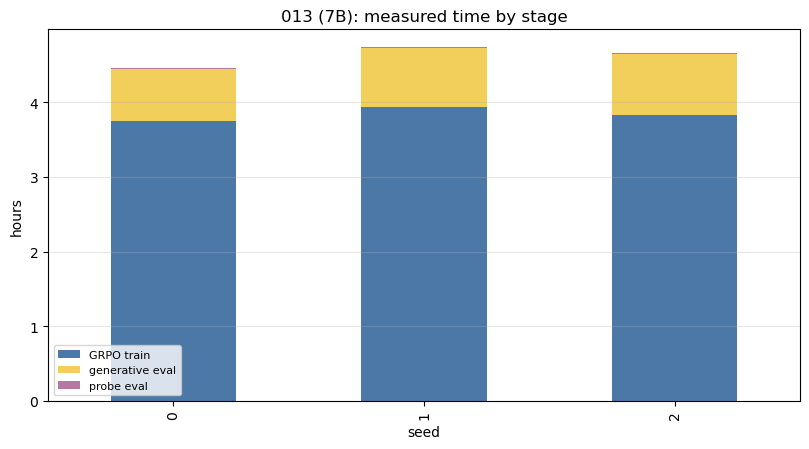

,GRPO train,generative eval,probe eval
seed,,,
0,3.753,0.694,0.011
1,3.942,0.788,0.011
2,3.833,0.812,0.011


In [15]:
# compare measured GRPO training and evaluation time across seeds
compute_rows = []
for seed, data in BASE.items():
    timings = data["manifest"]["timings_sec"]
    compute_rows.append({
        "seed": seed,
        "GRPO train": timings["grpo_train"] / 3600,
        "generative eval": timings["grpo_eval"] / 3600,
        "probe eval": timings["grpo_logprob_eval"] / 3600,
    })
compute_tbl = pd.DataFrame(compute_rows).set_index("seed")
ax = compute_tbl.plot(kind="bar", stacked=True, figsize=(8.2, 4.6), color=["#4C78A8", "#F2CF5B", "#B279A2"])
ax.set_ylabel("hours")
ax.set_xlabel("seed")
ax.set_title("013 (7B): measured time by stage")
ax.grid(alpha=0.3, axis="y")
ax.legend(fontsize=8)
fig = ax.get_figure()
fig.tight_layout()
save(fig, "fig12_compute_by_seed")
plt.show()

display(compute_tbl.round(3))


In [16]:
# keep the exact 7b endpoint values used by the figures in one table
endpoint_rows = []
for route, runs in (("base to GRPO", BASE), ("SFT to GRPO", WARM)):
    for seed, data in runs.items():
        row = {
            "route": route,
            "seed": seed,
            "overall": overall(data["preds"]),
            "format": float(np.mean([item["format_ok"] for item in data["preds"]])),
            "mean_length": float(np.mean([item["n_tokens"] for item in data["preds"]])),
            "probe_overall": overall(data["probe"]),
        }
        for tier in TIERS:
            row[tier] = grouped_accuracy(data["preds"], "tier", tier)
        endpoint_rows.append(row)
endpoint_tbl = pd.DataFrame(endpoint_rows).set_index(["route", "seed"])
display(endpoint_tbl.round(4))


overall  format  mean_length  probe_overall    easy  \
route        seed                                                        
base to GRPO 0      0.7988  0.9766     115.0743         0.7999  0.8885   
             1      0.7967  0.9756     139.4130         0.8020  0.8760   
             2      0.7771  0.9644     131.4639         0.8025  0.8646   
SFT to GRPO  0      0.8020  0.9841      66.4512         0.7999  0.8931   
             1      0.8052  0.9889      66.9135         0.7999  0.8919   
             2      0.8068  0.9846      65.4246         0.7956  0.8862   

                   medium    hard  
route        seed                  
base to GRPO 0     0.7635  0.6540  
             1     0.7603  0.6768  
             2     0.7570  0.6136  
SFT to GRPO  0     0.7767  0.6389  
             1     0.7767  0.6566  
             2     0.7980  0.6439

## Cross-referenced conclusion

All three 013 base-start runs completed normally on A100-80GB. Each has
exactly 500 GRPO steps and complete 1,884-item generative and probe
evaluations. No execution fallback was used.

Base-to-GRPO accuracy is 79.9%, 79.7% and 77.7%, compared with 76.9% for the
shared raw base. Format compliance is 97.7%, 97.6% and 96.4%, so the 7B model
learns the requested format reliably without the GSM8K warm start.

The registered matched comparison does not give one common 7B category. Warm
minus base is +0.3, +0.8 and +3.0 points. Seeds 0 and 1 are inconclusive after
Holm correction, while seed 2 is a material warm advantage. The earlier
single-seed tie isn't contradicted in seeds 0 and 1, but it does not
replicate as a common three-seed result.

The hard-tier route difference is -1.5, -2.0 and +3.0 points. Base-start is
ahead in two 7B pairs and warm-start is ahead in one. Across all four scales,
base-start is at or above warm-start on hard questions in 10 of 12 matched
pairs, so the direction is frequent but not universal.

The registered cross-scale shrinking rule is not met. Seed 0 and seed 2 have
negative slopes against log model size, but seed 1 has a positive slope. The
warm-start gradient is therefore mixed rather than seed-robust shrinking. At
1.5B and 3B all three pairs favour the warm route, while 0.5B and 7B have mixed
pair-level readings.

Base-route letter probe stays within 0.3 points of the shared raw-base
probe in every 7B seed. The 7B generative gain again appears without a
measurable increase in the encoded MMLU letter preference.
